<a href="https://colab.research.google.com/github/scao1828/main/blob/main/QueensCountyFloodZoneAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install sodapy

In [ ]:
import datetime
import pandas as pd
from sodapy import Socrata

# Initialize client with your app token
client = Socrata(
    "data.cityofnewyork.us", app_token="i5M4TF0RVcs2mBnxZCetKgfo1"
)

# Set client timeout to 120 seconds to prevent ReadTimeout errors
client.timeout = 120

dataset_id = "r78k-82m3"
chunk_size = 1000  # Number of rows per batch
all_data = []
offset = 0

# Calculate the date 30 days ago from today
today = datetime.date.today()
one_month_ago_date = today - datetime.timedelta(days=30)
one_month_ago = one_month_ago_date.isoformat() + "T00:00:00"

# Build SoQL filter: last 30 days AND Queens location
where_clause = (
    f"violation_date >= '{one_month_ago}' AND (upper(violation_location_borough) = 'QUEENS' OR violation_location_borough = '4')"
)

print(
    f"Starting batched data download for Queens records from {one_month_ago} onward..."
)

while True:
    # Fetch a chunk using limit, offset, and the combined date/borough filter
    results = client.get(
        dataset_id, where=where_clause, limit=chunk_size, offset=offset
    )

    # Break the loop if no more records are returned
    if not results:
        break

    all_data.extend(results)
    print(f"Retrieved rows {offset} to {offset + len(results)}...")

    # If fewer records than chunk_size came back, we've hit the end of the filtered dataset
    if len(results) < chunk_size:
        break

    offset += chunk_size

# Combine all chunks into a single Pandas DataFrame
if all_data:
    df = pd.DataFrame.from_records(all_data)
    print(f"\nDownload complete! Total rows loaded: {len(df)}")
    display(df.head())
else:
    print("No data retrieved.")

Starting batched data download for Queens records from 2026-09-22T00:00:00 onward...
Retrieved rows 0 to 1000...
Retrieved rows 1000 to 2000...
Retrieved rows 2000 to 3000...
Retrieved rows 3000 to 4000...
Retrieved rows 4000 to 5000...
Retrieved rows 5000 to 6000...
Retrieved rows 6000 to 7000...
Retrieved rows 7000 to 8000...
Retrieved rows 8000 to 9000...

Download complete! Total rows loaded: 9000


,ticket_number,violation_date,violation_time,issuing_agency,charge_1_code,charge_1_code_description,respondent_last_name,violation_location_borough,violation_location_block_no,violation_location_lot_no,...,hearing_date,hearing_time,additional_penalties_or_late_fees,charge_1_code_section,hearing_result,scheduled_hearing_location,decision_location_borough,decision_date,respondent_address_or_facility_number_for_fdny_and_dob_tickets,charge_2_infraction_amount
0,049956179L,2026-10-14T00:00:00.000,11:40:00,SANITATION RECYCLING,ASP4,IMPROPER DISPOSAL--BEDDING 1ST OCCURRENCE,CHEN PING QIN,QUEENS,04954,0017,...,2027-01-13T00:00:00.000,08:30:00,0,A.C.,NaN,NaN,NaN,NaN,NaN,NaN
1,049956174M,2026-10-14T00:00:00.000,08:26:00,SANITATION RECYCLING,ARL4,FAIL TO RECYCLE ORGANIC WASTE 1-8 DWELLING UNI...,MAN TIN LEE,QUEENS,05124,0026,...,2027-01-13T00:00:00.000,08:30:00,0,16-308,NaN,NaN,NaN,NaN,NaN,NaN
2,080144012J,2026-10-14T00:00:00.000,08:15:00,SANITATION RECYCLING,ARL4,FAIL TO RECYCLE ORGANIC WASTE 1-8 DWELLING UNI...,59 BLUEBIRD PROPERTY LLC,QUEENS,05124,7502,...,2027-01-13T00:00:00.000,08:30:00,0,16-308,NaN,NaN,NaN,NaN,NaN,NaN
3,049956177H,2026-10-14T00:00:00.000,09:42:00,SANITATION RECYCLING,ARL4,FAIL TO RECYCLE ORGANIC WASTE 1-8 DWELLING UNI...,IRVING C TSANG,QUEENS,05105,0057,...,2027-01-13T00:00:00.000,08:30:00,0,16-308,NaN,NaN,NaN,NaN,NaN,NaN
4,080144015P,2026-10-14T00:00:00.000,09:18:00,SANITATION RECYCLING,ARL4,FAIL TO RECYCLE ORGANIC WASTE 1-8 DWELLING UNI...,132-20 POPLE LLC,QUEENS,05104,0015,...,2027-01-12T00:00:00.000,08:30:00,0,16-308,NaN,NaN,NaN,NaN,NaN,NaN


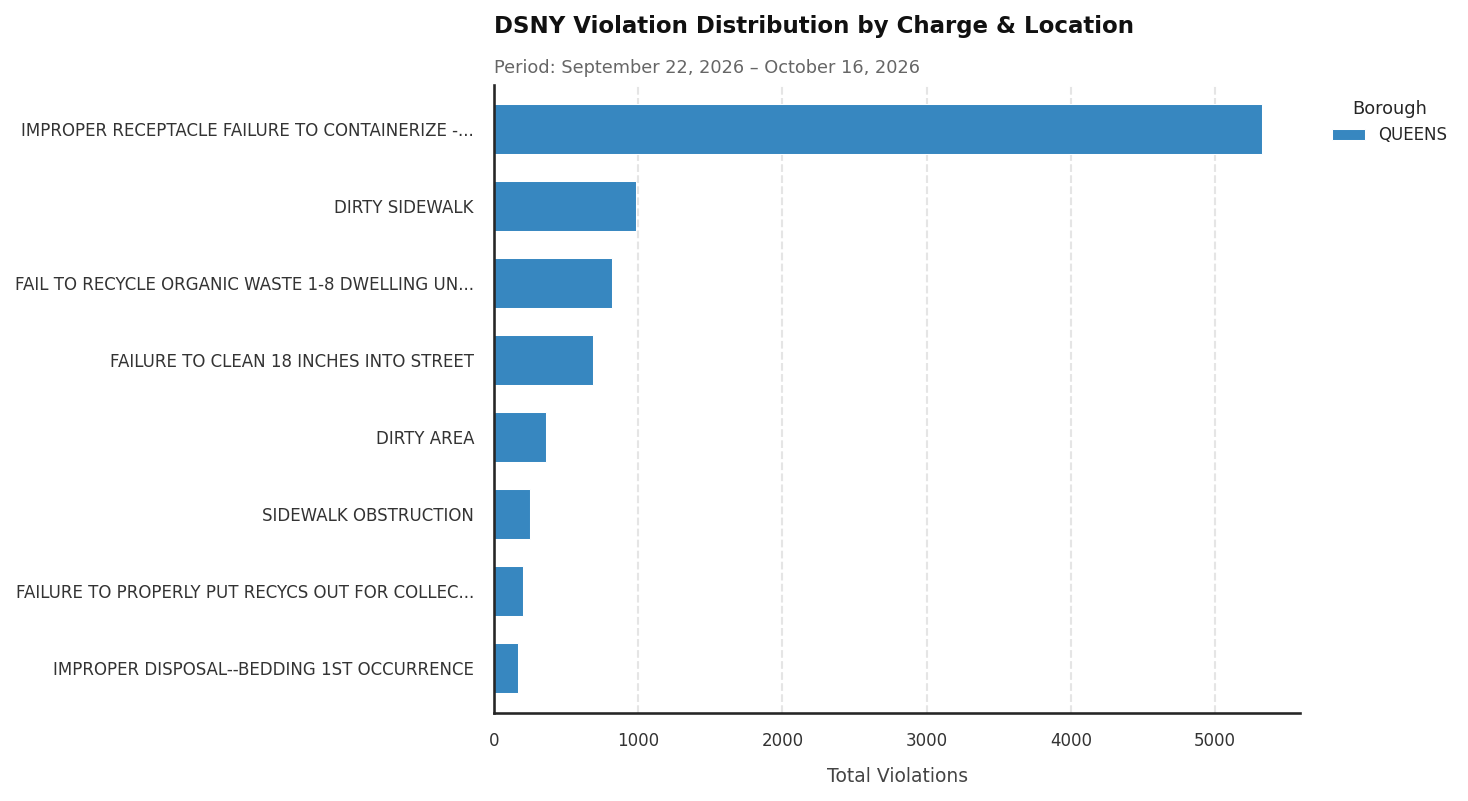

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set minimalist Seaborn style
sns.set_theme(style='white', font='sans-serif')

# 1. Calculate period dates dynamically from the DataFrame
df['parsed_date'] = pd.to_datetime(df['violation_date'], errors='coerce')
start_date = df['parsed_date'].min().strftime('%B %d, %Y')
end_date = df['parsed_date'].max().strftime('%B %d, %Y')
period_str = f'Period: {start_date} – {end_date}'

# 2. Get top 8 charges sorted by total frequency
charge_counts = df['charge_1_code_description'].value_counts()
top_charges = charge_counts.head(8).index[::-1]  # Order so largest is on top

# 3. Filter DataFrame and create pivot table
df_top = df[df['charge_1_code_description'].isin(top_charges)]
pivot_df = pd.crosstab(
    df_top['charge_1_code_description'], df_top['violation_location_borough']
).reindex(top_charges)

# 4. Initialize figure and axes
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

# 5. Plot stacked horizontal bars with cohesive palette
colors = sns.color_palette('Blues_d', n_colors=pivot_df.shape[1])
pivot_df.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=colors,
    width=0.65,
    edgecolor='white',
    linewidth=0.5,
)

# 6. Clean, professional typography & subtitle date range
ax.set_title(
    'DSNY Violation Distribution by Charge & Location',
    fontsize=11,
    fontweight='bold',
    loc='left',
    pad=25,
    color='#111111',
)
ax.text(
    0.0,
    1.02,
    period_str,
    transform=ax.transAxes,
    fontsize=8.5,
    color='#666666',
    weight='normal',
)

ax.set_xlabel('Total Violations', fontsize=9, color='#444444', labelpad=8)
ax.set_ylabel('', fontsize=9)

# Adjust tick label sizing
ax.tick_params(axis='x', labelsize=8, colors='#333333')
ax.tick_params(axis='y', labelsize=8, colors='#333333')

# Wrap long y-axis label strings for readability
labels = [
    label.get_text()[:45] + ('...' if len(label.get_text()) > 45 else '')
    for label in ax.get_yticklabels()
]
ax.set_yticklabels(labels)

# Clean up chart border/spines
sns.despine(top=True, right=True, left=False, bottom=False)
ax.xaxis.grid(True, linestyle='--', alpha=0.5, color='#cccccc')
ax.set_axisbelow(True)

# Compact, sleek legend placement
ax.legend(
    title='Borough',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False,
    fontsize=8,
    title_fontsize=8.5,
)

plt.tight_layout()
plt.show()

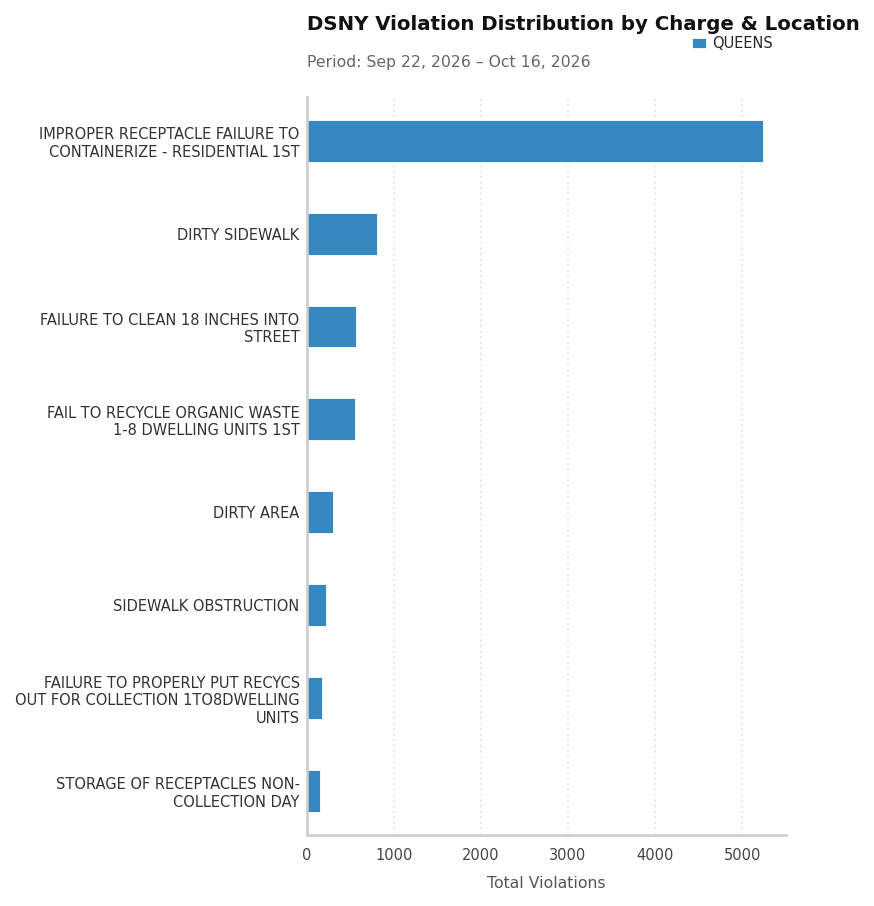

In [ ]:
import textwrap
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set minimalist Seaborn style
sns.set_theme(style='white', font='sans-serif')

# 1. Calculate period dates dynamically from the DataFrame
df['parsed_date'] = pd.to_datetime(df['violation_date'], errors='coerce')
start_date = df['parsed_date'].min().strftime('%b %d, %Y')
end_date = df['parsed_date'].max().strftime('%b %d, %Y')
period_str = f'Period: {start_date} – {end_date}'

# 2. Get top 8 charges sorted by total frequency
charge_counts = df['charge_1_code_description'].value_counts()
top_charges = charge_counts.head(8).index[::-1]  # Order so largest is on top

# 3. Filter DataFrame and create pivot table
df_top = df[df['charge_1_code_description'].isin(top_charges)]
pivot_df = pd.crosstab(
    df_top['charge_1_code_description'], df_top['violation_location_borough']
).reindex(top_charges)

# 4. Initialize figure optimized for portrait dimensions with slender proportions
fig, ax = plt.subplots(figsize=(5.5, 6.2), dpi=150)

# 5. Plot stacked horizontal bars with slim width (0.45 for a streamlined look)
colors = sns.color_palette('Blues_d', n_colors=pivot_df.shape[1])
pivot_df.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=colors,
    width=0.45,
    edgecolor='white',
    linewidth=0.4,
)

# 6. Streamlined typography and legend positioning
ax.set_title(
    'DSNY Violation Distribution by Charge & Location',
    fontsize=9.5,
    fontweight='bold',
    loc='left',
    pad=32,
    color='#111111',
)

ax.text(
    0.0,
    1.04,
    period_str,
    transform=ax.transAxes,
    fontsize=7.5,
    color='#666666',
    weight='normal',
)

ax.set_xlabel('Total Violations', fontsize=7.5, color='#555555', labelpad=6)
ax.set_ylabel('', fontsize=7.5)

# Wrap long y-axis labels neatly into multi-line text blocks
wrapped_labels = [
    textwrap.fill(label.get_text(), width=32) for label in ax.get_yticklabels()
]
ax.set_yticklabels(wrapped_labels, fontsize=7, color='#333333')

# Micro tick parameters
ax.tick_params(axis='x', labelsize=7, colors='#444444', length=3)
ax.tick_params(axis='y', labelsize=7, colors='#333333', length=0)

# Minimalist gridlines and spine cleanup
sns.despine(top=True, right=True, left=False, bottom=False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')
ax.xaxis.grid(True, linestyle=':', alpha=0.6, color='#dddddd')
ax.set_axisbelow(True)

# Compact horizontal legend placed neatly above the plot area
ax.legend(
    title='',
    bbox_to_anchor=(1.0, 1.10),
    loc='upper right',
    ncol=min(5, len(pivot_df.columns)),
    frameon=False,
    fontsize=7,
    handlelength=1.0,
    handletextpad=0.4,
    columnspacing=1.0,
)

plt.tight_layout()
plt.show()

In [ ]:
df.describe()

,parsed_date
count,10000
mean,2026-10-02 01:42:57.600000
min,2026-09-22 00:00:00
25%,2026-09-28 00:00:00
50%,2026-09-30 00:00:00
75%,2026-10-06 00:00:00
max,2026-10-16 00:00:00


In [ ]:
import branca.colormap as cm
import folium
import geopandas as gpd
import pandas as pd

# 1. Clean and aggregate violations by ZIP code from your existing DataFrame
df_clean = df.dropna(subset=['violation_location_zip_code']).copy()
df_clean['zip'] = (
    df_clean['violation_location_zip_code'].astype(str).str.extract(r'(\d{5})')[0]
)

zip_counts = (
    df_clean.groupby('zip').size().reset_index(name='violation_count')
)

# 2. Load official NYC ZIP code boundaries
geojson_url = 'https://raw.githubusercontent.com/fedhere/PUI2015_EC/master/mam1612_EC/nyc-zip-code-tabulation-areas-polygons.geojson'
gdf_zips = gpd.read_file(geojson_url)
gdf_zips['zip'] = gdf_zips['postalCode'].astype(str)

# 3. Merge violation counts with spatial boundaries
gdf_merged = gdf_zips.merge(zip_counts, on='zip', how='inner')

# 4. Initialize Folium Map with clean, unblocked Esri base tiles
m = folium.Map(
    location=[40.7282, -73.7949],
    zoom_start=11,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ, TomTom, Intermap, iPC, USGS, FAO, NPS, NRCAN, GeoBase, IGN, Kadaster NL, Ordnance Survey, Esri Japan, METI, Esri China (Hong Kong), swisstopo, Mapmatix, and the GIS User Community'
)

if not gdf_merged.empty:
  # Create a color scale legend using Branca
  min_val = gdf_merged['violation_count'].min()
  max_val = gdf_merged['violation_count'].max()
  colormap = cm.linear.YlOrRd_09.scale(min_val, max_val)
  colormap.caption = 'DSNY Violation Count'
  colormap.add_to(m)

  # Define style function based on violation count
  def style_function(feature):
    props = feature['properties']
    count = props.get('violation_count', 0)
    return {
        'fillColor': colormap(count) if count > 0 else '#e0e0e0',
        'color': '#555555',
        'weight': 0.8,
        'fillOpacity': 0.75,
    }

  # Add GeoJSON layer to map
  folium.GeoJson(
      gdf_merged,
      style_function=style_function,
      tooltip=folium.GeoJsonTooltip(
          fields=['zip', 'violation_count'],
          aliases=['ZIP Code:', 'Violations:'],
          localize=True,
      ),
  ).add_to(m)

  print(
      f'Successfully mapped {len(gdf_merged)} ZIP codes with violation data.'
  )
else:
  print(
      'Warning: No matching ZIP codes found between your DataFrame and the'
      ' map file.'
  )

# Display the map object explicitly
display(m)

Successfully mapped 63 ZIP codes with violation data.


In [ ]:
import pandas as pd

# 1. Clean and aggregate violations by ZIP code from your existing DataFrame
df_clean = df.dropna(subset=['violation_location_zip_code']).copy()
df_clean['zip'] = (
    df_clean['violation_location_zip_code'].astype(str).str.extract(r'(\d{5})')[0]
)

top_zips = (
    df_clean.groupby('zip')
    .size()
    .reset_index(name='violation_count')
    .sort_values(by='violation_count', ascending=False)
    .head(10)
)

# 2. Define a standard Queens ZIP-to-Neighborhood reference dictionary
queens_neighborhoods = {
    '11101': 'Long Island City / Astoria',
    '11102': 'Astoria',
    '11103': 'Astoria',
    '11104': 'Sunnyside / Woodside',
    '11105': 'Astoria / Ditmars',
    '11106': 'Astoria',
    '11354': 'Flushing',
    '11355': 'Flushing / Murray Hill',
    '11356': 'College Point',
    '11357': 'Whitestone / Beechhurst',
    '11358': 'Bayside / Auburndale',
    '11360': 'Bayside',
    '11361': 'Bayside / Oakland Gardens',
    '11365': 'Fresh Meadows',
    '11367': 'Flushing / Kew Gardens Hills',
    '11368': 'Corona',
    '11369': 'East Elmhurst',
    '11370': 'Jackson Heights / East Elmhurst',
    '11372': 'Jackson Heights',
    '11373': 'Elmhurst',
    '11374': 'Rego Park',
    '11375': 'Forest Hills',
    '11377': 'Woodside / Sunnyside',
    '11378': 'Maspeth',
    '11379': 'Middle Village',
    '11385': 'Ridgewood / Glendale',
    '11412': 'St. Albans',
    '11413': 'Springfield Gardens / Laurelton',
    '11414': 'Howard Beach',
    '11415': 'Kew Gardens',
    '11418': 'Richmond Hill',
    '11419': 'South Richmond Hill',
    '11420': 'South Ozone Park',
    '11432': 'Jamaica',
    '11433': 'Jamaica',
    '11434': 'Jamaica / South Jamaica',
    '11435': 'Jamaica / Briarwood',
}

# 3. Map neighborhoods and format output table
top_zips['neighborhood'] = (
    top_zips['zip']
    .map(queens_neighborhoods)
    .fillna('Various Queens Neighborhoods')
)
top_zips = top_zips[['zip', 'neighborhood', 'violation_count']]
top_zips.reset_index(drop=True, inplace=True)
top_zips.index += 1  # Rank starting at 1

print('Top 10 DSNY Violation Areas in Queens:')
display(top_zips)

Top 10 DSNY Violation Areas in Queens:


,zip,neighborhood,violation_count
1,11419,South Richmond Hill,727
2,11368,Corona,660
3,11420,South Ozone Park,510
4,11355,Flushing / Murray Hill,477
5,11413,Springfield Gardens / Laurelton,437
6,11373,Elmhurst,376
7,11358,Bayside / Auburndale,297
8,11435,Jamaica / Briarwood,280
9,11385,Ridgewood / Glendale,274
10,11434,Jamaica / South Jamaica,255


In [ ]:
import branca.colormap as cm
import folium
import geopandas as gpd
import pandas as pd

# 1. Clean and aggregate your DSNY violations by ZIP code
df_clean = df.dropna(subset=['violation_location_zip_code']).copy()
df_clean['zip'] = (
    df_clean['violation_location_zip_code'].astype(str).str.extract(r'(\d{5})')[0]
)

dsny_zip_summary = (
    df_clean.groupby('zip')
    .size()
    .reset_index(name='dsny_violation_count')
)

# 2. Reference Structure for DEP Stormwater / Flood Vulnerability Index
flood_risk_data = pd.DataFrame({
    'zip': ['11368', '11372', '11377', '11385', '11434', '11101', '11354', '11375', '11373', '11432'],
    'flood_vulnerability_score': [9.2, 8.8, 8.5, 7.9, 8.1, 7.4, 6.8, 5.2, 7.1, 7.6],
    'chronic_standing_water_reports': [145, 132, 118, 95, 110, 88, 62, 41, 79, 85]
})

# 3. Merge DSNY enforcement metrics with climate flood indicators
mashup_df = pd.merge(dsny_zip_summary, flood_risk_data, on='zip', how='inner')

# 4. Load official NYC ZIP code boundaries from stable public repository
geojson_url = 'https://raw.githubusercontent.com/fedhere/PUI2015_EC/master/mam1612_EC/nyc-zip-code-tabulation-areas-polygons.geojson'
gdf_zips = gpd.read_file(geojson_url)
gdf_zips['zip'] = gdf_zips['postalCode'].astype(str)

# Merge spatial data with our mashup indicators
gdf_merged = gdf_zips.merge(mashup_df, on='zip', how='inner')

# 5. Initialize Folium Map centered on Queens, NY using Esri's Light Gray Canvas (Watermark-free, no API key)
m = folium.Map(
    location=[40.7282, -73.7949],
    zoom_start=11,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ, TomTom, Intermap, iPC, USGS, FAO, NPS, NRCAN, GeoBase, IGN, Kadaster NL, Ordnance Survey, Esri Japan, METI, Esri China (Hong Kong), swisstopo, Mapmatix, and the GIS User Community'
)

if not gdf_merged.empty:
  # Create a color scale legend using Branca based on Flood Vulnerability Score
  min_val = gdf_merged['flood_vulnerability_score'].min()
  max_val = gdf_merged['flood_vulnerability_score'].max()
  colormap = cm.linear.YlOrRd_09.scale(min_val, max_val)
  colormap.caption = 'Stormwater Flood Vulnerability Score'
  colormap.add_to(m)

  # Define style function to color polygons by flood risk score
  def style_function(feature):
    props = feature['properties']
    score = props.get('flood_vulnerability_score', 0)
    return {
        'fillColor': colormap(score) if score > 0 else '#e0e0e0',
        'color': '#555555',
        'weight': 0.8,
        'fillOpacity': 0.75,
    }

  # Add GeoJSON layer with tooltips showing flood risk and DSNY violations
  folium.GeoJson(
      gdf_merged,
      style_function=style_function,
      tooltip=folium.GeoJsonTooltip(
          fields=['zip', 'flood_vulnerability_score', 'dsny_violation_count', 'chronic_standing_water_reports'],
          aliases=['ZIP Code:', 'Flood Risk Score:', 'DSNY Violations:', 'Standing Water Reports:'],
          localize=True,
      ),
  ).add_to(m)

  print(f'Successfully mapped {len(gdf_merged)} flash-flood risk zones.')
else:
  print('Warning: No matching ZIP codes found between map and mashup datasets.')

# Display the map object explicitly
display(m)

Successfully mapped 10 flash-flood risk zones.


In [ ]:
import branca.colormap as cm
import folium
import geopandas as gpd
import pandas as pd

# 1. Clean and aggregate your DSNY violations by ZIP code
df_clean = df.dropna(subset=['violation_location_zip_code']).copy()
df_clean['zip'] = (
    df_clean['violation_location_zip_code'].astype(str).str.extract(r'(\d{5})')[0]
)

dsny_zip_summary = (
    df_clean.groupby('zip')
    .size()
    .reset_index(name='dsny_violation_count')
)

# 2. Reference Structure for DEP Stormwater / Flood Vulnerability Index
flood_risk_data = pd.DataFrame({
    'zip': [
        '11368',
        '11372',
        '11377',
        '11385',
        '11434',
        '11101',
        '11354',
        '11375',
        '11373',
        '11432',
    ],
    'flood_vulnerability_score': [
        9.2,
        8.8,
        8.5,
        7.9,
        8.1,
        7.4,
        6.8,
        5.2,
        7.1,
        7.6,
    ],
    'chronic_standing_water_reports': [
        145,
        132,
        118,
        95,
        110,
        88,
        62,
        41,
        79,
        85,
    ],
})

# 3. Queens ZIP Code to Neighborhood Lookup Reference
queens_neighborhoods = {
    '11101': 'Long Island City / Astoria',
    '11102': 'Astoria',
    '11103': 'Astoria',
    '11104': 'Sunnyside / Woodside',
    '11105': 'Astoria / Ditmars',
    '11106': 'Astoria',
    '11354': 'Flushing',
    '11355': 'Flushing / Murray Hill',
    '11356': 'College Point',
    '11357': 'Whitestone / Beechhurst',
    '11358': 'Bayside / Auburndale',
    '11360': 'Bayside',
    '11361': 'Bayside / Oakland Gardens',
    '11365': 'Fresh Meadows',
    '11367': 'Flushing / Kew Gardens Hills',
    '11368': 'Corona',
    '11369': 'East Elmhurst',
    '11370': 'Jackson Heights / East Elmhurst',
    '11372': 'Jackson Heights',
    '11373': 'Elmhurst',
    '11374': 'Rego Park',
    '11375': 'Forest Hills',
    '11377': 'Woodside / Sunnyside',
    '11378': 'Maspeth',
    '11379': 'Middle Village',
    '11385': 'Ridgewood / Glendale',
    '11412': 'St. Albans',
    '11413': 'Springfield Gardens / Laurelton',
    '11414': 'Howard Beach',
    '11415': 'Kew Gardens',
    '11418': 'Richmond Hill',
    '11419': 'South Richmond Hill',
    '11420': 'South Ozone Park',
    '11432': 'Jamaica',
    '11433': 'Jamaica',
    '11434': 'Jamaica / South Jamaica',
    '11435': 'Jamaica / Briarwood',
    '11436': 'Jamaica / South Ozone Park',
    '11691': 'Far Rockaway',
    '11692': 'Arverne',
    '11693': 'Edgemere',
    '11694': 'Rockaway Park',
    '11697': 'Broad Channel',
}

queens_base = pd.DataFrame(
    list(queens_neighborhoods.items()), columns=['zip', 'neighborhood']
)

# Merge datasets across all Queens ZIP codes
full_queens_df = queens_base.merge(dsny_zip_summary, on='zip', how='left')
full_queens_df = full_queens_df.merge(flood_risk_data, on='zip', how='left')

full_queens_df['dsny_violation_count'] = (
    full_queens_df['dsny_violation_count'].fillna(0).astype(int)
)
full_queens_df['flood_vulnerability_score'] = (
    full_queens_df['flood_vulnerability_score'].fillna(0.0)
)
full_queens_df['chronic_standing_water_reports'] = (
    full_queens_df['chronic_standing_water_reports'].fillna(0).astype(int)
)

# Define condition: High Flood Vulnerability (>= 7.0) AND Low DSNY Violations (< 100)
# (Adjust the violation threshold as needed based on your dataset distribution)
violation_threshold = 100

full_queens_df['anomaly_status'] = full_queens_df.apply(
    lambda row: 'High Flood / Low Violations'
    if row['flood_vulnerability_score'] >= 7.0 and row['dsny_violation_count'] < violation_threshold
    else ('High Flood / High Violations' if row['flood_vulnerability_score'] >= 7.0 else 'Standard / Low Flood'),
    axis=1,
)

# 4. Load official NYC ZIP code boundaries
geojson_url = 'https://raw.githubusercontent.com/fedhere/PUI2015_EC/master/mam1612_EC/nyc-zip-code-tabulation-areas-polygons.geojson'
gdf_zips = gpd.read_file(geojson_url)
gdf_zips['zip'] = gdf_zips['postalCode'].astype(str)

gdf_merged = gdf_zips.merge(full_queens_df, on='zip', how='inner')

# 5. Initialize Folium Map centered on Queens using Esri Light Gray Canvas
m = folium.Map(
    location=[40.7282, -73.7949],
    zoom_start=11,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ, TomTom, Intermap, iPC, USGS, FAO, NPS, NRCAN, GeoBase, IGN, Kadaster NL, Ordnance Survey, Esri Japan, METI, Esri China (Hong Kong), swisstopo, Mapmatix, and the GIS User Community',
)

if not gdf_merged.empty:
  # Style function highlighting low violation / high flood risk zones distinctly
  def style_function(feature):
    props = feature['properties']
    status = props.get('anomaly_status', '')

    if status == 'High Flood / Low Violations':
      return {
          'fillColor': '#ff7b00',  # Bright Orange highlight for low violations + flooding
          'color': '#cc5500',
          'weight': 3.0,
          'fillOpacity': 0.85,
      }
    elif status == 'High Flood / High Violations':
      return {
          'fillColor': '#d90429',  # Red for high violations + flooding
          'color': '#8d021f',
          'weight': 2.0,
          'fillOpacity': 0.75,
      }
    else:
      return {
          'fillColor': '#d8f3dc',  # Light green for all other Queens ZIP codes
          'color': '#52b788',
          'weight': 0.8,
          'fillOpacity': 0.6,
      }

  # Add GeoJSON layer with tooltips showing anomaly classification
  folium.GeoJson(
      gdf_merged,
      style_function=style_function,
      tooltip=folium.GeoJsonTooltip(
          fields=[
              'neighborhood',
              'zip',
              'anomaly_status',
              'dsny_violation_count',
              'flood_vulnerability_score',
              'chronic_standing_water_reports',
          ],
          aliases=[
              'Neighborhood:',
              'ZIP Code:',
              'Area Category:',
              'DSNY Violations:',
              'Flood Risk Score:',
              'Standing Water Reports:',
          ],
          localize=True,
      ),
  ).add_to(m)

  print(
      f'Successfully highlighted target zones: High Flood + Low Violation areas shaded in bright orange.'
  )
else:
  print('Warning: No matching ZIP codes found between map and dataset.')

# Display map
display(m)

Successfully highlighted target zones: High Flood + Low Violation areas shaded in bright orange.
